# 01 — Khám phá dữ liệu Yoochoose (EDA hướng bài toán Popularity Bias & Embedding Geometry)

Notebook này khảo sát dữ liệu gốc **Yoochoose (RecSys Challenge 2015)** theo từng bước độc lập, mỗi bước trả lời đúng một câu hỏi cần thiết cho bài toán **SBR — Thiên lệch độ phổ biến & Hình học không gian Embedding**:

1. Thiết lập môi trường & nạp nhanh 33 triệu sự kiện bằng `pyarrow.csv`.
2. Đối chiếu vai trò `clicks` vs. `buys` để chốt nguồn chuỗi hành vi.
3. Kiểm toán trục thời gian, ranh giới 03:00 UTC và thứ tự timestamp trong phiên.
4. Khảo sát cấu trúc phiên, click lặp và thời lượng phiên.
5. Phân tích dịch chuyển chế độ ghi nhận `Category` theo tháng (`0`, `S`, `1..12`, `brand`).
6. Kiểm tra độ nhất quán `Category` cấp item & tỷ lệ chuyển tiếp cùng category.
7. Đo độ lệch phân bố độ phổ biến (`Raw Gini`, `Lorenz`, dải tần suất).
8. Phân tích riêng hiệu ứng khuếch đại độ phổ biến của nhãn `S` (Special Offer).
9. Khảo sát động lực 30 ngày cuối & tốc độ xuất hiện item mới (dự báo Natural Cold).
10. Mô phỏng ma trận đánh đổi giữa các lát cắt (`1/64`, `1/32`, `1/16`, `1/8`) và độ nhạy ngưỡng `min_item_frequency`.
11. Tổng hợp bảng quyết định **Phát hiện EDA → Quy tắc tiền xử lý** bàn giao cho `02_Xulydulieu.ipynb`.

## 1. Thiết lập môi trường, đường dẫn và cấu hình hiển thị

In [1]:
from __future__ import annotations

import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pv
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").is_file():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án DA-3.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import get_dataset_paths, ensure_output_dirs
from btl_k03.popularity_metrics import compute_gini_coefficient, compute_lorenz_curve

ensure_output_dirs("yoochoose")
YOO_PATHS = get_dataset_paths("yoochoose")
TABLES_DIR = YOO_PATHS["tables_dir"]
FIGURES_DIR = YOO_PATHS["figures_dir"]
CLICKS_PATH = YOO_PATHS["raw_clicks_file"]
BUYS_PATH = YOO_PATHS["raw_buys_file"]

print(f"CLICKS_PATH : {CLICKS_PATH}")
print(f"BUYS_PATH   : {BUYS_PATH}")
print(f"TABLES_DIR  : {TABLES_DIR}")
print(f"FIGURES_DIR : {FIGURES_DIR}")

CLICKS_PATH : D:\DA-3\data\raw\yoochoose-clicks.dat\yoochoose-clicks.dat
BUYS_PATH   : D:\DA-3\data\raw\yoochoose-buys.dat\yoochoose-buys.dat
TABLES_DIR  : D:\DA-3\results\yoochoose\tables
FIGURES_DIR : D:\DA-3\results\yoochoose\figures


## 2. Nạp nhanh toàn bộ 33 triệu sự kiện bằng PyArrow & kiểm tra giá trị thiếu

Dùng `pyarrow.csv` với kiểu dữ liệu gọn (`int32`, `timestamp[ms, tz=UTC]`, `dictionary<int32, string>`) giúp nạp toàn bộ 1,42 GB trong ~2–3 giây và giữ mức tiêu thụ RAM thấp.

In [2]:
t0 = time.perf_counter()

clicks_tbl = pv.read_csv(
    CLICKS_PATH,
    read_options=pv.ReadOptions(
        column_names=["session_id", "timestamp", "item_id", "category_raw"]
    ),
    convert_options=pv.ConvertOptions(
        column_types={
            "session_id": pa.int32(),
            "timestamp": pa.timestamp("ms", tz="UTC"),
            "item_id": pa.int32(),
            "category_raw": pa.dictionary(pa.int32(), pa.string()),
        }
    ),
)

sess_arr = clicks_tbl["session_id"].to_numpy(zero_copy_only=False)
ts_ms_arr = clicks_tbl["timestamp"].cast(pa.int64()).to_numpy(zero_copy_only=False)
item_arr = clicks_tbl["item_id"].to_numpy(zero_copy_only=False)
cat_chunked = clicks_tbl["category_raw"].combine_chunks()
cat_dict = cat_chunked.dictionary.to_pandas().astype(str).to_numpy()
cat_idx_arr = cat_chunked.indices.to_numpy(zero_copy_only=False)
clicks_nulls = {col: clicks_tbl[col].null_count for col in clicks_tbl.column_names}
del clicks_tbl, cat_chunked

buys_df = pv.read_csv(
    BUYS_PATH,
    read_options=pv.ReadOptions(
        column_names=["session_id", "timestamp", "item_id", "price", "quantity"]
    ),
    convert_options=pv.ConvertOptions(
        column_types={
            "session_id": pa.int32(),
            "timestamp": pa.timestamp("ms", tz="UTC"),
            "item_id": pa.int32(),
            "price": pa.int32(),
            "quantity": pa.int32(),
        }
    ),
).to_pandas()

df = pd.DataFrame(
    {
        "session_id": sess_arr,
        "ts_ms": ts_ms_arr,
        "item_id": item_arr,
        "cat_idx": cat_idx_arr,
    }
)

n_clicks = len(df)
n_sessions = int(df["session_id"].nunique())
n_items = int(df["item_id"].nunique())
min_ts = pd.Timestamp(int(ts_ms_arr.min()), unit="ms", tz="UTC")
max_ts = pd.Timestamp(int(ts_ms_arr.max()), unit="ms", tz="UTC")

print(f"Thời gian nạp clicks + buys : {time.perf_counter() - t0:.2f}s")
print(f"Null trong clicks           : {clicks_nulls}")
print(f"Null trong buys             : {buys_df.isna().sum().to_dict()}")
print(f"Số dòng / phiên / item      : {n_clicks:,} / {n_sessions:,} / {n_items:,}")

Thời gian nạp clicks + buys : 4.94s
Null trong clicks           : {'session_id': 0, 'timestamp': 0, 'item_id': 0, 'category_raw': 0}
Null trong buys             : {'session_id': 0, 'timestamp': 0, 'item_id': 0, 'price': 0, 'quantity': 0}
Số dòng / phiên / item      : 33,003,944 / 9,249,729 / 52,739


## 3. Đối chiếu vai trò giữa `yoochoose-clicks.dat` và `yoochoose-buys.dat`

Kiểm tra mức độ giao nhau giữa hai file và xác nhận lý do chỉ sử dụng `clicks` để xây dựng chuỗi SBR chính (tương đương `train-item-views.csv` bên Diginetica).

In [3]:
n_buys = len(buys_df)
n_buy_sessions = int(buys_df["session_id"].nunique())
n_buy_items = int(buys_df["item_id"].nunique())

click_sess_set = set(df["session_id"].unique())
click_item_set = set(df["item_id"].unique())
buy_sess_in_clicks_pct = float(buys_df["session_id"].isin(click_sess_set).mean() * 100.0)
buy_item_in_clicks_pct = float(buys_df["item_id"].isin(click_item_set).mean() * 100.0)
del click_sess_set, click_item_set

overview_df = pd.DataFrame(
    [
        {
            "file": "yoochoose-clicks.dat",
            "events": n_clicks,
            "sessions": n_sessions,
            "items": n_items,
            "min_ts_utc": str(min_ts),
            "max_ts_utc": str(max_ts),
            "vai_tro": "Chuỗi tương tác SBR chính (tương đương train-item-views.csv)",
        },
        {
            "file": "yoochoose-buys.dat",
            "events": n_buys,
            "sessions": n_buy_sessions,
            "items": n_buy_items,
            "min_ts_utc": str(buys_df["timestamp"].min()),
            "max_ts_utc": str(buys_df["timestamp"].max()),
            "vai_tro": "Sự kiện mua hàng (conversion), không trộn vào chuỗi next-click",
        },
    ]
)
overview_df.to_csv(TABLES_DIR / "eda_raw_overview.csv", index=False)
display(overview_df)

print(f"Tỷ lệ phiên có phát sinh mua hàng : {n_buy_sessions / n_sessions * 100:.2f}%")
print(f"Buys khớp session trong clicks    : {buy_sess_in_clicks_pct:.2f}%")
print(f"Buys khớp item trong clicks       : {buy_item_in_clicks_pct:.2f}%")

,file,events,sessions,items,min_ts_utc,max_ts_utc,vai_tro
0,yoochoose-clicks.dat,33003944,9249729,52739,2014-04-01 03:00:00.124000+00:00,2014-09-30 02:59:59.430000+00:00,Chuỗi tương tác SBR chính (tương đương train-i...
1,yoochoose-buys.dat,1150753,509696,19949,2014-04-01 03:05:31.743000+00:00,2014-09-30 02:35:12.859000+00:00,"Sự kiện mua hàng (conversion), không trộn vào ..."


Tỷ lệ phiên có phát sinh mua hàng : 5.51%
Buys khớp session trong clicks    : 100.00%
Buys khớp item trong clicks       : 100.00%


## 4. Kiểm toán trục thời gian, ranh giới ngày `03:00 UTC` và thứ tự sự kiện trong phiên

Bên Diginetica, 58,21% phiên bị đảo thứ tự `timeframe` trong file gốc. Cell này kiểm tra xem Yoochoose có bị đảo thứ tự, cắt đoạn phiên (`interleaved`), trùng mili-giây (`same_ts`) hay có ranh giới ngày đặc biệt nào không.

In [4]:
same_sess = sess_arr[1:] == sess_arr[:-1]
n_session_blocks = int((~same_sess).sum()) + 1
interleaved_blocks = n_session_blocks - n_sessions
out_of_order_ts = int((same_sess & (ts_ms_arr[1:] < ts_ms_arr[:-1])).sum())
tied_ts = int((same_sess & (ts_ms_arr[1:] == ts_ms_arr[:-1])).sum())
exact_dup_events = int(
    (same_sess & (ts_ms_arr[1:] == ts_ms_arr[:-1]) & (item_arr[1:] == item_arr[:-1])).sum()
)

# Kiểm tra số sự kiện ở 3 ngày đầu và 3 ngày cuối theo lịch UTC
days_epoch = ts_ms_arr // 86_400_000
uniq_days, day_inv = np.unique(days_epoch, return_inverse=True)
day_dates = pd.to_datetime(uniq_days, unit="D", utc=True)
day_counts = np.bincount(day_inv, minlength=len(uniq_days))
edge_days_df = pd.DataFrame({"utc_date": day_dates.strftime("%Y-%m-%d"), "events": day_counts})

order_audit_df = pd.DataFrame(
    [
        ("Khoảng thời gian UTC", f"{min_ts}  →  {max_ts}", "Biên ngày tự nhiên tại 03:00 UTC (182 ngày tròn 24h)"),
        ("Số block phiên liên tiếp vs. duy nhất", f"{n_session_blocks:,} / {n_sessions:,}", f"Interleaved = {interleaved_blocks:,} (không phiên nào bị xé lẻ)"),
        ("Sự kiện đảo thứ tự thời gian trong phiên", f"{out_of_order_ts:,}", "File raw đã theo thứ tự thời gian (khác Diginetica 58.21%)"),
        ("Cặp sự kiện trùng chính xác mili-giây", f"{tied_ts:,}", "Dùng khóa phá hòa row_order khi sắp xếp ổn định"),
        ("Bản ghi trùng tuyệt đối (session, ts, item)", f"{exact_dup_events:,}", "Cần loại bỏ ở bước làm sạch"),
    ],
    columns=["chi_tieu", "gia_tri", "nhan_xet"],
)
order_audit_df.to_csv(TABLES_DIR / "eda_time_and_order_audit.csv", index=False)
display(order_audit_df)

print("3 ngày cuối theo UTC (chú ý 2014-09-30 chỉ có 3 giờ 00:00–02:59 UTC):")
display(edge_days_df.tail(4))

,chi_tieu,gia_tri,nhan_xet
0,Khoảng thời gian UTC,2014-04-01 03:00:00.124000+00:00 → 2014-09-3...,Biên ngày tự nhiên tại 03:00 UTC (182 ngày trò...
1,Số block phiên liên tiếp vs. duy nhất,"9,249,729 / 9,249,729",Interleaved = 0 (không phiên nào bị xé lẻ)
2,Sự kiện đảo thứ tự thời gian trong phiên,0,File raw đã theo thứ tự thời gian (khác Digine...
3,Cặp sự kiện trùng chính xác mili-giây,"1,117",Dùng khóa phá hòa row_order khi sắp xếp ổn định
4,"Bản ghi trùng tuyệt đối (session, ts, item)",68,Cần loại bỏ ở bước làm sạch


3 ngày cuối theo UTC (chú ý 2014-09-30 chỉ có 3 giờ 00:00–02:59 UTC):


,utc_date,events
179,2014-09-27,122198
180,2014-09-28,66239
181,2014-09-29,78597
182,2014-09-30,2220


## 5. Cấu trúc độ dài phiên, click lặp và thời lượng phiên

Đo tỷ lệ phiên độ dài 1 (không tạo được cặp prefix → target), phân bố độ dài phiên để kiểm chứng `max_seq_length = 50`, tỷ lệ click lặp liên tiếp và tỷ lệ phiên đi qua nửa đêm UTC.

,chi_tieu,gia_tri,ham_y
0,Phiên độ dài = 1,"1,259,711 (13.62%)",Thấp hơn Diginetica (29.23%); loại bỏ trước kh...
1,Click lặp item liên tiếp,"4,032,400 (12.22%)",Giữ click lặp khác timestamp để bảo toàn hành ...
2,Phiên đi qua nửa đêm UTC,"6,078 (0.07%)",Gán nguyên phiên theo timestamp cuối phiên để ...
3,Độ dài phiên (median / p75 / p90 / p99 / max),2 / 4 / 7 / 18 / 200,max_seq_length = 50 bao phủ >99.9% phiên
4,Thời lượng phiên (phút: median / p90 / p99),2.13 / 16.55 / 58.84,"Hành vi phiên ngắn, tập trung"


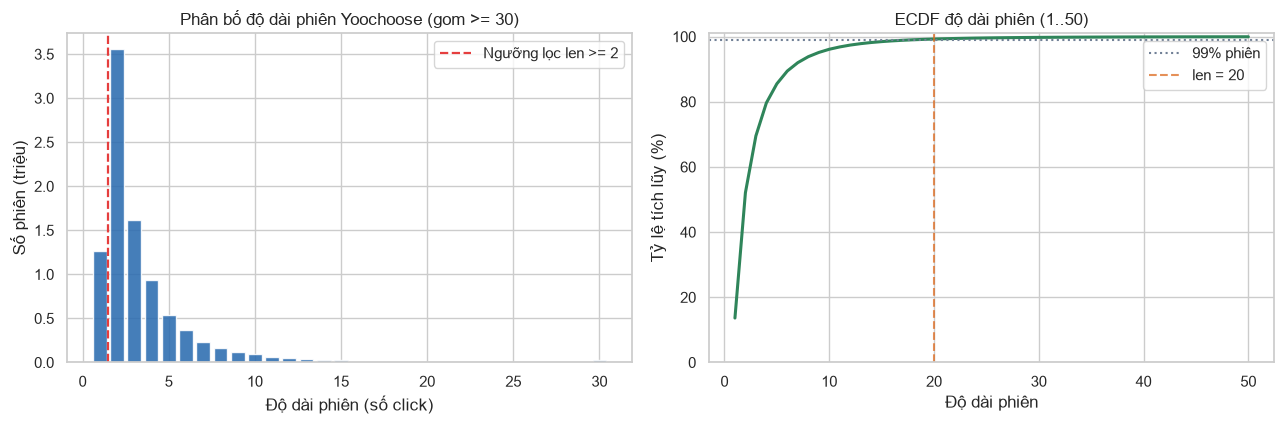

In [5]:
sess_grp = df.groupby("session_id", sort=False)
sess_len = sess_grp.size()
sess_min_ts = sess_grp["ts_ms"].min()
sess_max_ts = sess_grp["ts_ms"].max()
sess_dur_min = (sess_max_ts - sess_min_ts) / 60_000.0

consec_repeat_clicks = int((same_sess & (item_arr[1:] == item_arr[:-1])).sum())
cross_utc_midnight = int(((sess_min_ts // 86_400_000) != (sess_max_ts // 86_400_000)).sum())
n_len1 = int((sess_len == 1).sum())

sess_struct_df = pd.DataFrame(
    [
        ("Phiên độ dài = 1", f"{n_len1:,} ({n_len1 / n_sessions * 100:.2f}%)", "Thấp hơn Diginetica (29.23%); loại bỏ trước khi chia split"),
        ("Click lặp item liên tiếp", f"{consec_repeat_clicks:,} ({consec_repeat_clicks / n_clicks * 100:.2f}%)", "Giữ click lặp khác timestamp để bảo toàn hành vi quay lại"),
        ("Phiên đi qua nửa đêm UTC", f"{cross_utc_midnight:,} ({cross_utc_midnight / n_sessions * 100:.2f}%)", "Gán nguyên phiên theo timestamp cuối phiên để không cắt phiên"),
        ("Độ dài phiên (median / p75 / p90 / p99 / max)", f"{sess_len.median():.0f} / {sess_len.quantile(0.75):.0f} / {sess_len.quantile(0.9):.0f} / {sess_len.quantile(0.99):.0f} / {sess_len.max():.0f}", "max_seq_length = 50 bao phủ >99.9% phiên"),
        ("Thời lượng phiên (phút: median / p90 / p99)", f"{sess_dur_min.median():.2f} / {sess_dur_min.quantile(0.9):.2f} / {sess_dur_min.quantile(0.99):.2f}", "Hành vi phiên ngắn, tập trung"),
    ],
    columns=["chi_tieu", "gia_tri", "ham_y"],
)
sess_struct_df.to_csv(TABLES_DIR / "eda_session_structure.csv", index=False)
display(sess_struct_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
vc_len = sess_len.clip(upper=30).value_counts().sort_index()
axes[0].bar(vc_len.index, vc_len.values / 1e6, color="#2b6cb0", alpha=0.88)
axes[0].axvline(1.5, color="#e53e3e", linestyle="--", linewidth=1.6, label="Ngưỡng lọc len >= 2")
axes[0].set_title("Phân bố độ dài phiên Yoochoose (gom >= 30)")
axes[0].set_xlabel("Độ dài phiên (số click)")
axes[0].set_ylabel("Số phiên (triệu)")
axes[0].legend()

len_vals = np.arange(1, 51)
ecdf_vals = [(sess_len <= L).mean() * 100.0 for L in len_vals]
axes[1].plot(len_vals, ecdf_vals, color="#2f855a", linewidth=2.2)
axes[1].axhline(99.0, color="#718096", linestyle=":", label="99% phiên")
axes[1].axvline(20, color="#dd6b20", linestyle="--", alpha=0.75, label="len = 20")
axes[1].set_title("ECDF độ dài phiên (1..50)")
axes[1].set_xlabel("Độ dài phiên")
axes[1].set_ylabel("Tỷ lệ tích lũy (%)")
axes[1].set_ylim(0, 101)
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_session_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Phân tích chế độ ghi nhận `Category` theo thời gian (Phát hiện cốt lõi #1)

Theo đặc tả RecSys 2015, cột 4 của Yoochoose chứa 4 chế độ trộn lẫn:
- `'0'`: thiếu/không rõ danh mục
- `'S'`: sản phẩm trong khu vực ưu đãi đặc biệt (Special Offer)
- `'1'..'12'`: 12 danh mục sản phẩm chuẩn
- Số nguyên 8–10 chữ số: mã thương hiệu (`brand`)

Vì phân tích hình học embedding (Cosine cùng/khác category & khoảng cách tới tâm category ở File 07–08) phụ thuộc trực tiếp vào chất lượng `category`, ta cần kiểm tra xem 4 chế độ này phân bố theo từng tháng như thế nào.

,cat_regime,events,event_share_pct,unique_raw_codes
0,0_missing,16337653,49.5021,1
1,S_special,10769610,32.6313,1
2,1_12_regular,5820377,17.6354,12
3,brand_long_id,76304,0.2312,325


,month,events,zero_pct,S_pct,reg_pct,brand_pct
0,2014-04,5973371,100.0000,0.0000,0.0000,0.0000
1,2014-05,5544429,100.0000,0.0000,0.0000,0.0000
2,2014-06,5127025,78.4333,11.6023,9.5773,0.3871
3,2014-07,4434056,5.8808,54.0463,38.8730,1.1999
4,2014-08,6646541,5.0323,64.8039,30.1329,0.0309
5,2014-09,5278522,3.8520,65.7589,30.3665,0.0226


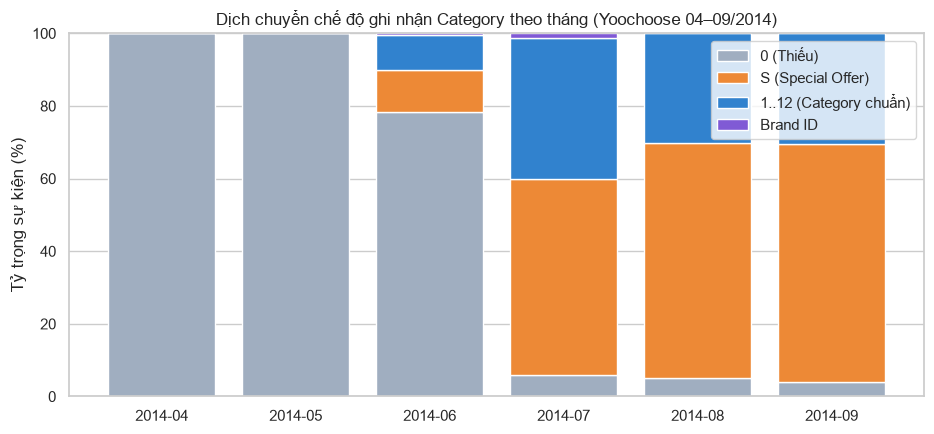

In [6]:
reg_set = {str(i) for i in range(1, 13)}
dict_type = np.array(
    [0 if v == "0" else (1 if v == "S" else (2 if v in reg_set else 3)) for v in cat_dict],
    dtype=np.int8,
)
ev_type = dict_type[cat_idx_arr]
df["ev_type"] = ev_type

type_labels = {0: "0_missing", 1: "S_special", 2: "1_12_regular", 3: "brand_long_id"}
cat_regime_df = pd.DataFrame(
    [
        {
            "cat_regime": label,
            "events": int((ev_type == code).sum()),
            "event_share_pct": float((ev_type == code).mean() * 100.0),
            "unique_raw_codes": int((dict_type == code).sum()),
        }
        for code, label in type_labels.items()
    ]
)
cat_regime_df.to_csv(TABLES_DIR / "eda_category_regime_overall.csv", index=False)
display(cat_regime_df)

daily_cat_df = pd.DataFrame(
    {
        "date": day_dates.strftime("%Y-%m-%d"),
        "month": day_dates.strftime("%Y-%m"),
        "events": day_counts,
        "zero": np.bincount(day_inv, weights=(ev_type == 0), minlength=len(uniq_days)).astype(np.int64),
        "S": np.bincount(day_inv, weights=(ev_type == 1), minlength=len(uniq_days)).astype(np.int64),
        "reg": np.bincount(day_inv, weights=(ev_type == 2), minlength=len(uniq_days)).astype(np.int64),
        "brand": np.bincount(day_inv, weights=(ev_type == 3), minlength=len(uniq_days)).astype(np.int64),
    }
)
monthly_cat_df = daily_cat_df.groupby("month")[["events", "zero", "S", "reg", "brand"]].sum().reset_index()
for col in ("zero", "S", "reg", "brand"):
    monthly_cat_df[f"{col}_pct"] = monthly_cat_df[col] / monthly_cat_df["events"] * 100.0
monthly_cat_df.to_csv(TABLES_DIR / "eda_category_regime_by_month.csv", index=False)
display(monthly_cat_df[["month", "events", "zero_pct", "S_pct", "reg_pct", "brand_pct"]])

fig, ax = plt.subplots(figsize=(9.5, 4.5))
x = np.arange(len(monthly_cat_df))
b0 = monthly_cat_df["zero_pct"].to_numpy()
b1 = monthly_cat_df["S_pct"].to_numpy()
b2 = monthly_cat_df["reg_pct"].to_numpy()
b3 = monthly_cat_df["brand_pct"].to_numpy()

ax.bar(x, b0, label="0 (Thiếu)", color="#a0aec0")
ax.bar(x, b1, bottom=b0, label="S (Special Offer)", color="#ed8936")
ax.bar(x, b2, bottom=b0 + b1, label="1..12 (Category chuẩn)", color="#3182ce")
ax.bar(x, b3, bottom=b0 + b1 + b2, label="Brand ID", color="#805ad5")
ax.set_xticks(x)
ax.set_xticklabels(monthly_cat_df["month"])
ax.set_ylabel("Tỷ trọng sự kiện (%)")
ax.set_title("Dịch chuyển chế độ ghi nhận Category theo tháng (Yoochoose 04–09/2014)")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_category_regime_by_month.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Độ nhất quán `Category` cấp item & cấu trúc chuyển tiếp cùng Category

Kiểm tra hai câu hỏi quan trọng để thiết kế quy tắc ánh xạ `category_id` cho mỗi item:
1. Các item mang nhãn `'S'` hoặc `brand` có đồng thời sở hữu category chuẩn `1..12` không? (Nếu có, ta không nên gom chúng vào nhóm giả `'S'` mà phải khôi phục category ngữ nghĩa `1..12`!)
2. Trong chuỗi click thực tế, khi người dùng chuyển từ item này sang item **khác**, xác suất hai item đó thuộc **cùng category `1..12`** là bao nhiêu?

,chi_tieu,so_item,ty_le_pct
0,Item có ít nhất 1 click non-0,42857,81.2624
1,Item có category chuẩn 1..12,42471,80.5305
2,Item có nhãn S (Special Offer),2984,5.6581
3,Item S đồng thời có category chuẩn 1..12,2845,95.3418
4,Item brand đồng thời có category chuẩn 1..12,6977,96.3541
5,Item có đúng 1 category 1..12 duy nhất (trong ...,39493,92.9882


Tỷ lệ chuyển tiếp khác item (non-self-repeat) nhưng CÙNG category 1..12: 79.60% (trên 18,282,634 cặp chuyển tiếp).


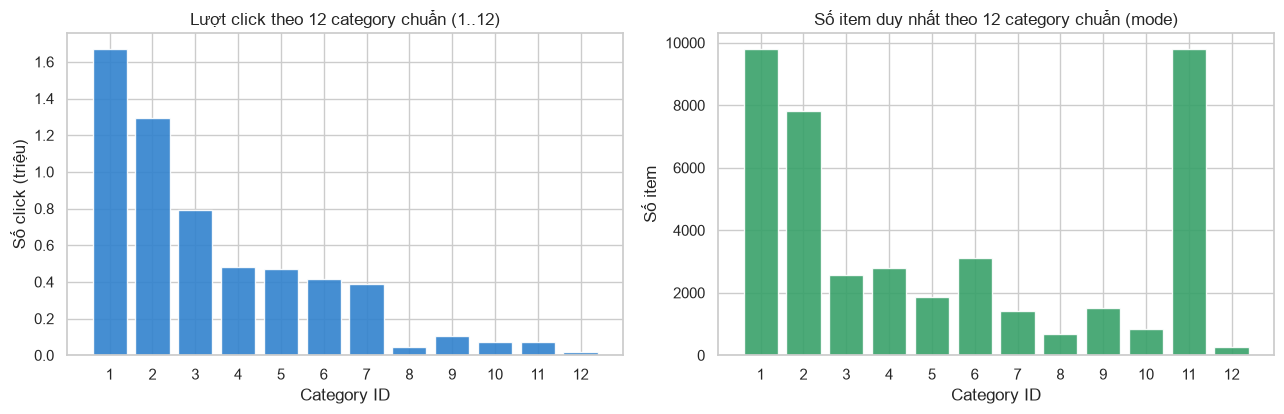

In [7]:
s_items = set(item_arr[ev_type == 1])
reg_items = set(item_arr[ev_type == 2])
brand_items = set(item_arr[ev_type == 3])
non0_items = set(item_arr[ev_type != 0])

reg_sub = df.loc[ev_type == 2, ["item_id", "cat_idx"]]
reg_nunique_per_item = reg_sub.groupby("item_id", sort=False)["cat_idx"].nunique()
single_reg_pct = float((reg_nunique_per_item == 1).mean() * 100.0)

reg_mode_idx = (
    reg_sub.groupby(["item_id", "cat_idx"], sort=False)
    .size()
    .reset_index(name="cnt")
    .sort_values(["item_id", "cnt", "cat_idx"], ascending=[True, False, True])
    .drop_duplicates("item_id")
    .set_index("item_id")["cat_idx"]
)
item_reg_cat = pd.Series(item_arr).map(reg_mode_idx).fillna(-1).to_numpy(dtype=np.int32)
diff_item_trans = same_sess & (item_arr[1:] != item_arr[:-1])
both_have_reg = diff_item_trans & (item_reg_cat[1:] >= 0) & (item_reg_cat[:-1] >= 0)
same_reg_trans_rate = float(
    (item_reg_cat[1:][both_have_reg] == item_reg_cat[:-1][both_have_reg]).mean() * 100.0
)

item_cat_summary = pd.DataFrame(
    [
        ("Item có ít nhất 1 click non-0", len(non0_items), len(non0_items) / n_items * 100.0),
        ("Item có category chuẩn 1..12", len(reg_items), len(reg_items) / n_items * 100.0),
        ("Item có nhãn S (Special Offer)", len(s_items), len(s_items) / n_items * 100.0),
        ("Item S đồng thời có category chuẩn 1..12", len(s_items & reg_items), len(s_items & reg_items) / max(1, len(s_items)) * 100.0),
        ("Item brand đồng thời có category chuẩn 1..12", len(brand_items & reg_items), len(brand_items & reg_items) / max(1, len(brand_items)) * 100.0),
        ("Item có đúng 1 category 1..12 duy nhất (trong số có 1..12)", int((reg_nunique_per_item == 1).sum()), single_reg_pct),
    ],
    columns=["chi_tieu", "so_item", "ty_le_pct"],
)
item_cat_summary.to_csv(TABLES_DIR / "eda_item_category_consistency.csv", index=False)
display(item_cat_summary)
print(
    f"Tỷ lệ chuyển tiếp khác item (non-self-repeat) nhưng CÙNG category 1..12: "
    f"{same_reg_trans_rate:.2f}% (trên {int(both_have_reg.sum()):,} cặp chuyển tiếp)."
)

reg_counts_by_id = (
    pd.Series(cat_dict[cat_idx_arr[ev_type == 2]]).astype(int).value_counts().sort_index()
)
reg_items_by_id = (
    pd.Series(cat_dict[reg_mode_idx.to_numpy()]).astype(int).value_counts().sort_index()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(reg_counts_by_id.index.astype(str), reg_counts_by_id.values / 1e6, color="#3182ce", alpha=0.9)
axes[0].set_title("Lượt click theo 12 category chuẩn (1..12)")
axes[0].set_xlabel("Category ID")
axes[0].set_ylabel("Số click (triệu)")

axes[1].bar(reg_items_by_id.index.astype(str), reg_items_by_id.values, color="#38a169", alpha=0.9)
axes[1].set_title("Số item duy nhất theo 12 category chuẩn (mode)")
axes[1].set_xlabel("Category ID")
axes[1].set_ylabel("Số item")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_regular_categories_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 8. Phân bố độ phổ biến đầu vào (Popularity Skew), Long-Tail và đường cong Lorenz

Đo trực tiếp mức độ tập trung lượt click trên catalog Yoochoose để đối chiếu với Diginetica (`Raw Gini = 0,726`, `63,80%` item có tần suất `< 5`).

Yoochoose Raw Gini = 0.8987 (Diginetica = 0.7260) | Median = 22 | P90 = 960 | Max = 147,419 | Item freq < 5: 28.02%


,top_item_pct,so_item,click_share_pct
0,1,527,34.9495
1,5,2637,72.5656
2,10,5274,85.4259
3,20,10548,94.1870


,freq_band,items,item_share_pct,clicks,click_share_pct
0,1,5657,10.7264,5657,0.0171
1,2-4,9118,17.2889,25437,0.0771
2,5-19,10801,20.4801,106225,0.3219
3,20-99,9605,18.2123,468551,1.4197
4,100-999,12427,23.5632,4344096,13.1624
5,>=1000,5131,9.7290,28053978,85.0019


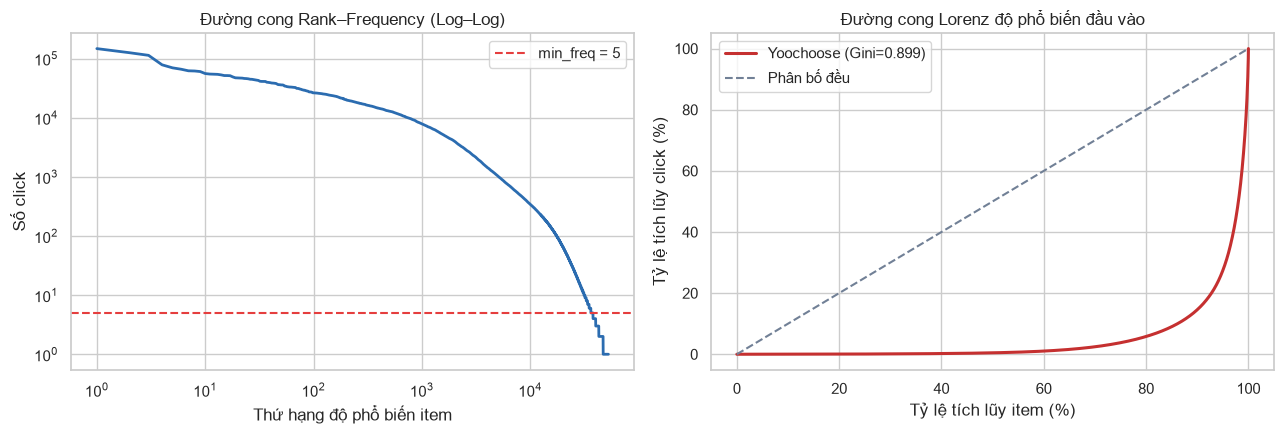

In [8]:
item_freq = df["item_id"].value_counts()
freq_vals = item_freq.to_numpy(dtype=np.float64)
raw_gini = compute_gini_coefficient(freq_vals)
lx, ly = compute_lorenz_curve(freq_vals)

sorted_desc = np.sort(freq_vals)[::-1]
cum_share = np.cumsum(sorted_desc) / sorted_desc.sum() * 100.0
conc_df = pd.DataFrame(
    [
        {
            "top_item_pct": pct,
            "so_item": max(1, int(round(len(sorted_desc) * pct / 100.0))),
            "click_share_pct": float(cum_share[max(1, int(round(len(sorted_desc) * pct / 100.0))) - 1]),
        }
        for pct in (1, 5, 10, 20)
    ]
)
conc_df.to_csv(TABLES_DIR / "eda_popularity_concentration.csv", index=False)

bands = [(1, 1, "1"), (2, 4, "2-4"), (5, 19, "5-19"), (20, 99, "20-99"), (100, 999, "100-999"), (1000, 10**9, ">=1000")]
band_df = pd.DataFrame(
    [
        {
            "freq_band": lbl,
            "items": int(((freq_vals >= lo) & (freq_vals <= hi)).sum()),
            "item_share_pct": float(((freq_vals >= lo) & (freq_vals <= hi)).mean() * 100.0),
            "clicks": int(freq_vals[(freq_vals >= lo) & (freq_vals <= hi)].sum()),
            "click_share_pct": float(freq_vals[(freq_vals >= lo) & (freq_vals <= hi)].sum() / freq_vals.sum() * 100.0),
        }
        for lo, hi, lbl in bands
    ]
)
band_df.to_csv(TABLES_DIR / "eda_frequency_bands.csv", index=False)

print(
    f"Yoochoose Raw Gini = {raw_gini:.4f} (Diginetica = 0.7260) | "
    f"Median = {np.median(freq_vals):.0f} | P90 = {np.quantile(freq_vals, 0.9):.0f} | "
    f"Max = {freq_vals.max():,.0f} | Item freq < 5: {(freq_vals < 5).mean()*100:.2f}%"
)
display(conc_df)
display(band_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].loglog(np.arange(1, len(sorted_desc) + 1), sorted_desc, color="#2b6cb0", linewidth=2)
axes[0].axhline(5, color="#e53e3e", linestyle="--", label="min_freq = 5")
axes[0].set_title("Đường cong Rank–Frequency (Log–Log)")
axes[0].set_xlabel("Thứ hạng độ phổ biến item")
axes[0].set_ylabel("Số click")
axes[0].legend()

axes[1].plot(lx * 100, ly * 100, color="#c53030", linewidth=2.2, label=f"Yoochoose (Gini={raw_gini:.3f})")
axes[1].plot([0, 100], [0, 100], linestyle="--", color="#718096", label="Phân bố đều")
axes[1].set_title("Đường cong Lorenz độ phổ biến đầu vào")
axes[1].set_xlabel("Tỷ lệ tích lũy item (%)")
axes[1].set_ylabel("Tỷ lệ tích lũy click (%)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_popularity_skew_lorenz.png", dpi=160, bbox_inches="tight")
plt.show()

## 9. Hiệu ứng khuếch đại độ phổ biến của nhóm `S` (Special Offer) — Đặc trưng riêng của Yoochoose

Khác với Diginetica, Yoochoose có cơ chế khuyến mãi `'S'`. Cell này đo xem tỷ trọng nhỏ các sản phẩm `'S'` đang tập trung bao nhiêu phần trăm tổng lượt click, giúp lý giải nguồn gốc cấu trúc của Popularity Bias trên Yoochoose.

,nhom_item,so_item,ty_le_catalog_pct,tong_click,ty_trong_click_pct,median_freq,mean_freq
0,Từng gắn nhãn S (Special Offer),2984,5.6581,18898124,57.2602,"3,655.0000","6,333.1515"
1,Không bao giờ gắn nhãn S,49755,94.3419,14105820,42.7398,17.0000,283.5056


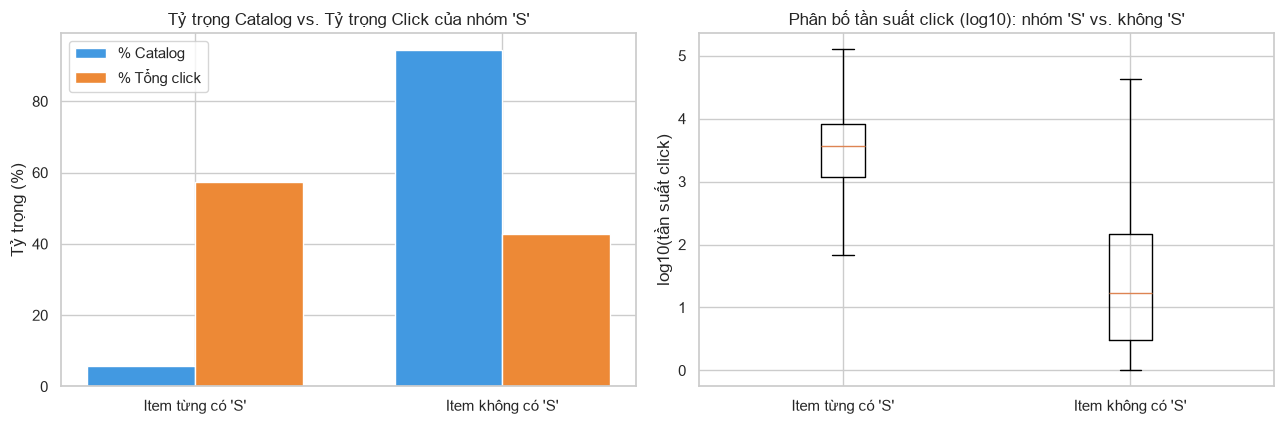

In [9]:
is_s_item = item_freq.index.isin(s_items)
s_compare_df = pd.DataFrame(
    [
        {
            "nhom_item": "Từng gắn nhãn S (Special Offer)",
            "so_item": int(is_s_item.sum()),
            "ty_le_catalog_pct": float(is_s_item.mean() * 100.0),
            "tong_click": int(freq_vals[is_s_item].sum()),
            "ty_trong_click_pct": float(freq_vals[is_s_item].sum() / freq_vals.sum() * 100.0),
            "median_freq": float(np.median(freq_vals[is_s_item])),
            "mean_freq": float(np.mean(freq_vals[is_s_item])),
        },
        {
            "nhom_item": "Không bao giờ gắn nhãn S",
            "so_item": int((~is_s_item).sum()),
            "ty_le_catalog_pct": float((~is_s_item).mean() * 100.0),
            "tong_click": int(freq_vals[~is_s_item].sum()),
            "ty_trong_click_pct": float(freq_vals[~is_s_item].sum() / freq_vals.sum() * 100.0),
            "median_freq": float(np.median(freq_vals[~is_s_item])),
            "mean_freq": float(np.mean(freq_vals[~is_s_item])),
        },
    ]
)
s_compare_df.to_csv(TABLES_DIR / "eda_special_offer_popularity_comparison.csv", index=False)
display(s_compare_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x_pos = np.arange(2)
w = 0.35
axes[0].bar(x_pos - w / 2, s_compare_df["ty_le_catalog_pct"], w, label="% Catalog", color="#4299e1")
axes[0].bar(x_pos + w / 2, s_compare_df["ty_trong_click_pct"], w, label="% Tổng click", color="#ed8936")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["Item từng có 'S'", "Item không có 'S'"])
axes[0].set_ylabel("Tỷ trọng (%)")
axes[0].set_title("Tỷ trọng Catalog vs. Tỷ trọng Click của nhóm 'S'")
axes[0].legend()

box_data = [np.log10(freq_vals[is_s_item]), np.log10(freq_vals[~is_s_item])]
axes[1].boxplot(box_data, tick_labels=["Item từng có 'S'", "Item không có 'S'"], showfliers=False)
axes[1].set_ylabel("log10(tần suất click)")
axes[1].set_title("Phân bố tần suất click (log10): nhóm 'S' vs. không 'S'")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_special_offer_amplification.png", dpi=160, bbox_inches="tight")
plt.show()

## 10. Động lực 30 ngày cuối & tốc độ xuất hiện item mới (dự báo Natural Cold)

Khảo sát độ ổn định lưu lượng theo ngày, mức độ đầy đủ category và số lượng item mới lần đầu xuất hiện trong 30 ngày cuối tháng 09/2014.

,date,events,non0_pct,new_items
173,2014-09-21,326405,96.5877,83
174,2014-09-22,272782,96.6101,92
175,2014-09-23,44413,95.5756,62
176,2014-09-24,188687,96.1211,106
177,2014-09-25,180986,95.6809,98
178,2014-09-26,135716,94.5703,93
179,2014-09-27,122198,92.3395,60
180,2014-09-28,66239,94.4308,22
181,2014-09-29,78597,94.8662,35
182,2014-09-30,2220,94.6847,1


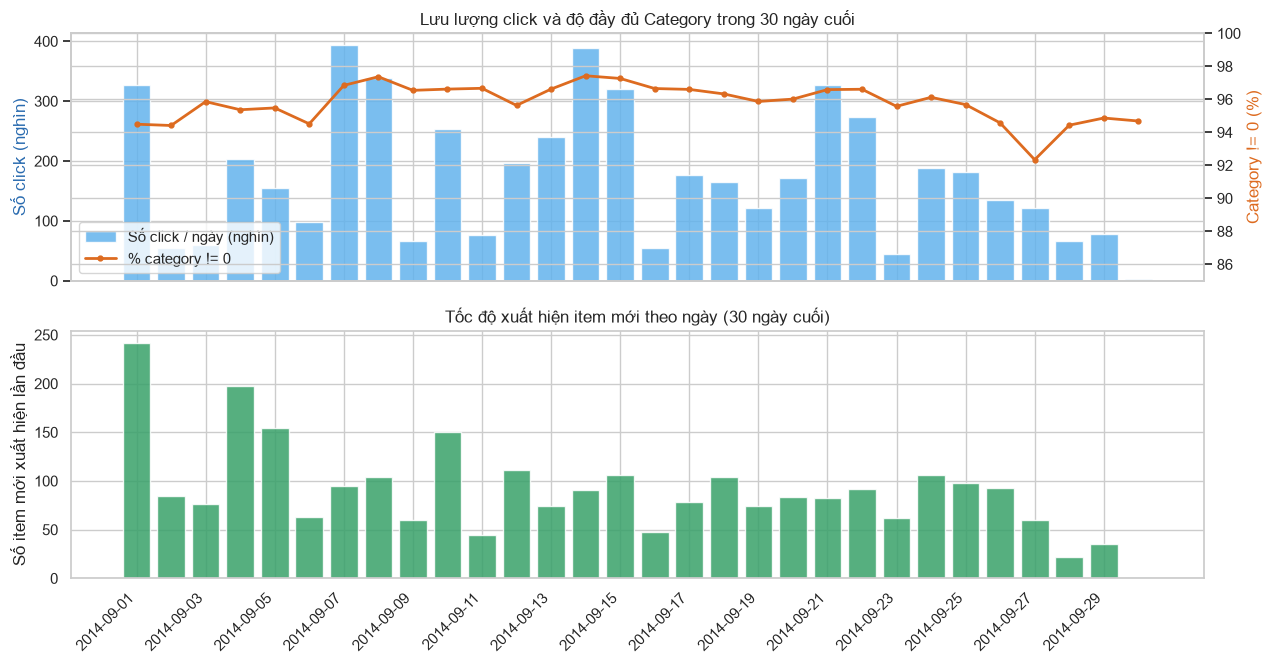

In [10]:
daily_cat_df["non0_pct"] = (daily_cat_df["events"] - daily_cat_df["zero"]) / daily_cat_df["events"] * 100.0
first_day_per_item = df.groupby("item_id", sort=False)["ts_ms"].min() // 86_400_000
new_items_per_day = first_day_per_item.value_counts()
daily_cat_df["new_items"] = pd.Series(uniq_days).map(new_items_per_day).fillna(0).astype(np.int64).to_numpy()

daily_last30 = daily_cat_df.tail(30).copy()
daily_last30.to_csv(TABLES_DIR / "eda_daily_last30.csv", index=False)
display(daily_last30[["date", "events", "non0_pct", "new_items"]].tail(10))

fig, axes = plt.subplots(2, 1, figsize=(13, 6.8), sharex=True)
idx = np.arange(len(daily_last30))

axes[0].bar(idx, daily_last30["events"] / 1e3, color="#63b3ed", alpha=0.85, label="Số click / ngày (nghìn)")
axes[0].set_ylabel("Số click (nghìn)", color="#2b6cb0")
ax0_r = axes[0].twinx()
ax0_r.plot(idx, daily_last30["non0_pct"], color="#dd6b20", marker="o", markersize=3.5, linewidth=2, label="% category != 0")
ax0_r.set_ylabel("Category != 0 (%)", color="#dd6b20")
ax0_r.set_ylim(85, 100)
l1, lb1 = axes[0].get_legend_handles_labels()
l2, lb2 = ax0_r.get_legend_handles_labels()
axes[0].legend(l1 + l2, lb1 + lb2, loc="lower left")
axes[0].set_title("Lưu lượng click và độ đầy đủ Category trong 30 ngày cuối")

axes[1].bar(idx, daily_last30["new_items"], color="#38a169", alpha=0.85)
axes[1].set_ylabel("Số item mới xuất hiện lần đầu")
axes[1].set_xticks(idx[::2])
axes[1].set_xticklabels(daily_last30["date"].iloc[::2], rotation=45, ha="right")
axes[1].set_title("Tốc độ xuất hiện item mới theo ngày (30 ngày cuối)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_daily_activity_and_new_items.png", dpi=160, bbox_inches="tight")
plt.show()

## 11. Ma trận đánh đổi lát cắt (`1/64`..`1/8`) và độ nhạy ngưỡng `min_item_frequency`

Vì tháng 04–06 thiếu category nặng và toàn bộ 33 triệu dòng quá lớn cho GPU 2 GB VRAM, ta mô phỏng trực tiếp các lát cắt chuẩn của văn liệu SBR (`1/64`, `1/32`, `1/16`, `1/8`) để chọn cấu hình vừa sạch category, vừa có quy mô mẫu tương đương Diginetica (~450k train examples, ~40k test queries).

,phuong_an,bat_dau_utc,raw_sessions,pre_cold_train_items,train_items_reg12_pct,train_items_non0_pct,pre_cold_train_examples,pre_cold_val_examples,pre_cold_test_examples
0,"1/64 (val=1d, test=1d)",2014-09-25,144527,7213,84.0288,92.0283,230224,43372,52941
1,"1/32 (val=1d, test=1d)",2014-09-22,289054,10582,88.0930,93.3661,559513,44597,54357
2,"1/16 (val=1d, test=1d)",2014-09-17,578108,14257,90.5310,93.8066,1251050,45292,55153
3,"1/16 (val=2d, test=2d)",2014-09-17,578108,13058,90.0674,93.6667,1066624,174457,91396
4,"1/8 (val=2d, test=2d)",2014-09-08,1156216,17351,91.7238,94.0810,2498965,177829,92712



Độ nhạy ngưỡng min_item_frequency trên lát cắt Yoochoose 1/32:


,min_item_frequency,train_events,train_sessions,train_items,item_reg12_pct,train_examples
0,2,759434,186144,16200,90.0926,573290
1,3,753260,184584,13496,89.4487,568676
2,5,741697,182184,10582,88.0930,559513
3,10,713669,176585,6921,84.5832,537084


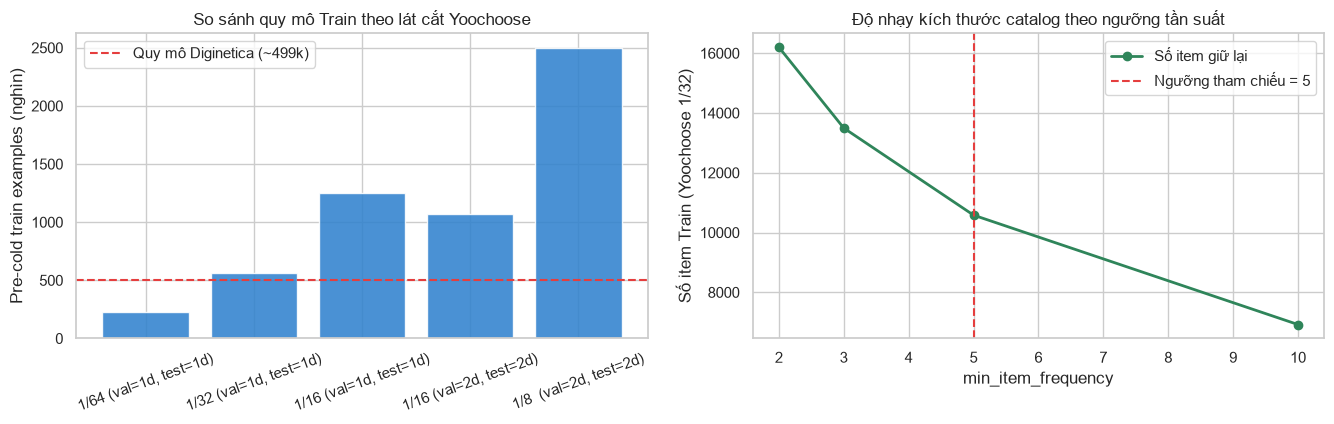

In [11]:
sess_last_sorted = sess_max_ts.sort_values()
max_ts_ms = int(sess_last_sorted.iloc[-1])
DAY_MS = 86_400_000


def fixed_point_filter(sub_df: pd.DataFrame, min_len: int = 2, min_freq: int = 5) -> pd.DataFrame:
    d = sub_df
    while True:
        prev_n = len(d)
        sc = d["session_id"].value_counts()
        d = d.loc[d["session_id"].isin(sc[sc >= min_len].index)]
        ic = d["item_id"].value_counts()
        d = d.loc[d["item_id"].isin(ic[ic >= min_freq].index)]
        if len(d) == prev_n:
            break
    return d


subset_rows = []
for label, denom, val_d, test_d in [
    ("1/64 (val=1d, test=1d)", 64, 1, 1),
    ("1/32 (val=1d, test=1d)", 32, 1, 1),
    ("1/16 (val=1d, test=1d)", 16, 1, 1),
    ("1/16 (val=2d, test=2d)", 16, 2, 2),
    ("1/8  (val=2d, test=2d)", 8, 2, 2),
]:
    k = len(sess_last_sorted) // denom
    cutoff_start = pd.Timestamp(int(sess_last_sorted.iloc[-k]), unit="ms", tz="UTC")
    keep_sids = set(sess_last_sorted.index[-k:])
    sub = df.loc[df["session_id"].isin(keep_sids)]
    sl = sub["session_id"].value_counts()
    sub = sub.loc[sub["session_id"].isin(sl[sl >= 2].index)]
    s_end = sub.groupby("session_id")["ts_ms"].transform("max")

    test_cut = max_ts_ms - test_d * DAY_MS
    val_cut = test_cut - val_d * DAY_MS
    tr = fixed_point_filter(sub.loc[s_end <= val_cut], min_len=2, min_freq=5)
    warm_set = set(tr["item_id"].unique())
    tr_reg_pct = tr.loc[tr["ev_type"] == 2, "item_id"].nunique() / max(1, len(warm_set)) * 100.0
    tr_non0_pct = tr.loc[tr["ev_type"] != 0, "item_id"].nunique() / max(1, len(warm_set)) * 100.0

    va = sub.loc[(s_end > val_cut) & (s_end <= test_cut) & sub["item_id"].isin(warm_set)]
    va_sl = va["session_id"].value_counts()
    va = va.loc[va["session_id"].isin(va_sl[va_sl >= 2].index)]

    te = sub.loc[(s_end > test_cut) & sub["item_id"].isin(warm_set)]
    te_sl = te["session_id"].value_counts()
    te = te.loc[te["session_id"].isin(te_sl[te_sl >= 2].index)]

    subset_rows.append(
        {
            "phuong_an": label,
            "bat_dau_utc": str(cutoff_start)[:10],
            "raw_sessions": k,
            "pre_cold_train_items": len(warm_set),
            "train_items_reg12_pct": tr_reg_pct,
            "train_items_non0_pct": tr_non0_pct,
            "pre_cold_train_examples": len(tr) - int(tr["session_id"].nunique()),
            "pre_cold_val_examples": len(va) - int(va["session_id"].nunique()),
            "pre_cold_test_examples": len(te) - int(te["session_id"].nunique()),
        }
    )

subset_compare_df = pd.DataFrame(subset_rows)
subset_compare_df.to_csv(TABLES_DIR / "eda_subset_tradeoff.csv", index=False)
display(subset_compare_df)

# Độ nhạy ngưỡng min_item_frequency trên lát cắt khuyến nghị 1/32
k32 = len(sess_last_sorted) // 32
sub32 = df.loc[df["session_id"].isin(set(sess_last_sorted.index[-k32:]))]
sl32 = sub32["session_id"].value_counts()
sub32 = sub32.loc[sub32["session_id"].isin(sl32[sl32 >= 2].index)]
s_end32 = sub32.groupby("session_id")["ts_ms"].transform("max")
tr32_raw = sub32.loc[s_end32 <= (max_ts_ms - 2 * DAY_MS)]

thresh_rows = []
for mf in (2, 3, 5, 10):
    f_tr = fixed_point_filter(tr32_raw, min_len=2, min_freq=mf)
    n_it = int(f_tr["item_id"].nunique())
    thresh_rows.append(
        {
            "min_item_frequency": mf,
            "train_events": len(f_tr),
            "train_sessions": int(f_tr["session_id"].nunique()),
            "train_items": n_it,
            "item_reg12_pct": f_tr.loc[f_tr["ev_type"] == 2, "item_id"].nunique() / max(1, n_it) * 100.0,
            "train_examples": len(f_tr) - int(f_tr["session_id"].nunique()),
        }
    )
thresh_df = pd.DataFrame(thresh_rows)
thresh_df.to_csv(TABLES_DIR / "eda_threshold_sensitivity_1_32.csv", index=False)
print("\nĐộ nhạy ngưỡng min_item_frequency trên lát cắt Yoochoose 1/32:")
display(thresh_df)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
axes[0].bar(subset_compare_df["phuong_an"], subset_compare_df["pre_cold_train_examples"] / 1e3, color="#3182ce", alpha=0.88)
axes[0].axhline(498.8, color="#e53e3e", linestyle="--", label="Quy mô Diginetica (~499k)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Pre-cold train examples (nghìn)")
axes[0].set_title("So sánh quy mô Train theo lát cắt Yoochoose")
axes[0].legend()

axes[1].plot(thresh_df["min_item_frequency"], thresh_df["train_items"], marker="o", color="#2f855a", linewidth=2, label="Số item giữ lại")
axes[1].axvline(5, color="#e53e3e", linestyle="--", label="Ngưỡng tham chiếu = 5")
axes[1].set_xlabel("min_item_frequency")
axes[1].set_ylabel("Số item Train (Yoochoose 1/32)")
axes[1].set_title("Độ nhạy kích thước catalog theo ngưỡng tần suất")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "eda_subset_and_threshold_tradeoff.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Kết luận EDA → Bảng quy tắc tiền xử lý bàn giao sang `02_Xulydulieu.ipynb`

In [12]:
decisions = [
    (
        "Tháng 04–05 thiếu 100% category='0', tháng 06 thiếu 78.4%; tháng 07–09 đạt ~95–96% non-zero",
        "Dùng lát cắt gần nhất Yoochoose 1/32 (2014-09-22..30): vừa sạch category vừa cho ~420k train examples & ~41k test queries tương đương Diginetica",
    ),
    (
        "0 phiên bị cắt đoạn, 0 đảo thứ tự timestamp; có 1.117 cặp trùng ms và 68 bản ghi trùng tuyệt đối",
        "Sắp xếp ổn định (session_id, ts_ms, row_order); loại trùng tuyệt đối (session, ts, item); giữ click lặp khác timestamp",
    ),
    (
        "13.62% phiên chỉ có 1 click",
        "Lọc session_length >= 2 trước khi chia tập và lọc fixed-point trên Train với min_item_frequency = 5",
    ),
    (
        "Dữ liệu kết thúc lúc 2014-09-30 02:59:59Z (tạo mẩu 3h nếu cắt theo lịch UTC)",
        "Chia temporal split theo cửa sổ 24 giờ neo vào max_ts (1 ngày validation + 1 ngày test cuối), gán nguyên phiên theo timestamp cuối",
    ),
    (
        ">95% item 'S' và >96% item 'brand' đều có category chuẩn 1..12; 93% item có đúng 1 category chuẩn",
        "Phân giải category chỉ từ Train: ưu tiên mode(1..12) > S_only(13) > brand_only(14) > unknown(0); lưu cờ has_regular_category & ever_special_offer",
    ),
    (
        "Raw Gini = 0.899 (lệch mạnh hơn Diginetica 0.726); 5.7% item 'S' chiếm 55–66% click cuối chuỗi",
        "Áp dụng Controlled Cold-start 20% phân tầng theo category (seed=2024) + chia rare/medium/popular chỉ từ final train",
    ),
    (
        "yoochoose-buys.dat chỉ chiếm 5.5% phiên và là conversion",
        "Chỉ dùng yoochoose-clicks.dat để tạo chuỗi huấn luyện/đánh giá next-click công bằng với Diginetica",
    ),
]

decision_df = pd.DataFrame(decisions, columns=["phat_hien_eda", "quy_tac_tien_xu_ly_nb02"])
decision_df.to_csv(TABLES_DIR / "eda_to_preprocessing_decisions.csv", index=False)
display(decision_df)
print("\nĐã lưu toàn bộ bảng và biểu đồ EDA vào:", YOO_PATHS["results_dir"])

,phat_hien_eda,quy_tac_tien_xu_ly_nb02
0,"Tháng 04–05 thiếu 100% category='0', tháng 06 ...",Dùng lát cắt gần nhất Yoochoose 1/32 (2014-09-...
1,"0 phiên bị cắt đoạn, 0 đảo thứ tự timestamp; c...","Sắp xếp ổn định (session_id, ts_ms, row_order)..."
2,13.62% phiên chỉ có 1 click,Lọc session_length >= 2 trước khi chia tập và ...
3,Dữ liệu kết thúc lúc 2014-09-30 02:59:59Z (tạo...,Chia temporal split theo cửa sổ 24 giờ neo vào...
4,>95% item 'S' và >96% item 'brand' đều có cate...,Phân giải category chỉ từ Train: ưu tiên mode(...
5,Raw Gini = 0.899 (lệch mạnh hơn Diginetica 0.7...,Áp dụng Controlled Cold-start 20% phân tầng th...
6,yoochoose-buys.dat chỉ chiếm 5.5% phiên và là ...,Chỉ dùng yoochoose-clicks.dat để tạo chuỗi huấ...



Đã lưu toàn bộ bảng và biểu đồ EDA vào: D:\DA-3\results\yoochoose
